In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import nltk
from sklearn.preprocessing import LabelBinarizer
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize,sent_tokenize
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Unzipping corpora/wordnet.zip.


True

In [3]:
#loading The Dataset:

fake = pd.read_csv('/content/drive/MyDrive/sem2/eng/lab1/Fake.csv', delimiter = ',')
true = pd.read_csv('/content/drive/MyDrive/sem2/eng/lab1/True.csv', delimiter = ',')


In [4]:
#observing the top 5 rows of fake data:

fake.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [5]:
#observing the top 5 rows of true data:
true.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [6]:
#add extra column target
fake['target'] = 0
true['target'] = 1
#merge data
df = pd.DataFrame()
df = true.append(fake)


In [7]:
#observing the top 5 rows of all data:
df.head()

,title,text,subject,date,target
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


In [8]:
#Checking the shape of loaded data frames:
print(df.shape)


(44898, 5)


In [9]:
#Exploring the data:
df.info()


<class 'pandas.core.frame.DataFrame'>
Int64Index: 44898 entries, 0 to 23480
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   target   44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 2.1+ MB


In [10]:
from sklearn.utils import shuffle
# Shuffle the data
df = shuffle(df).reset_index(drop=True)
df.head()


,title,text,subject,date,target
0,BLACK TRUMP SUPPORTER Goes On Tirade Over CNN’...,"On June 10, people in at least 27 cities are g...",left-news,"Jun 10, 2017",0
1,Obamacare Officially Bans Transgender Discrim...,While Republicans whine and complain that thei...,News,"May 14, 2016",0
2,May hails new optimism in Brexit talks after deal,LONDON (Reuters) - Prime Minister Theresa May ...,worldnews,"December 11, 2017",1
3,Kenya president: elections will go ahead despi...,NAIROBI (Reuters) - Kenyan President Uhuru Ken...,worldnews,"October 10, 2017",1
4,EU lawmakers see little progress in Sri Lanka ...,COLOMBO (Reuters) - European lawmakers said on...,worldnews,"November 2, 2017",1


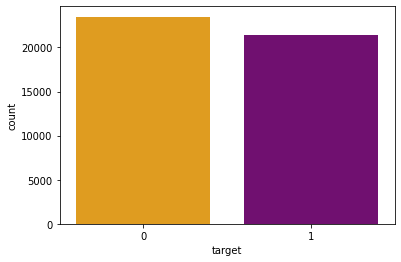

In [11]:
#This method shows the count of observations in each category
sns.countplot(x='target',data=df,palette=['orange','purple'])


In [12]:
#check the null values in the sample by summing null values
df.isnull().sum()


title      0
text       0
subject    0
date       0
target     0
dtype: int64

In [13]:
#check the types of columns
df.dtypes


title      object
text       object
subject    object
date       object
target      int64
dtype: object

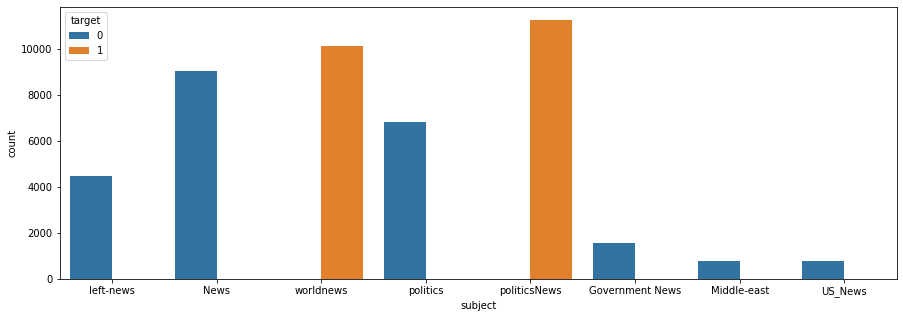

In [14]:
plt.figure(figsize=(15,5))
sns.countplot(x='subject',data=df,hue='target')

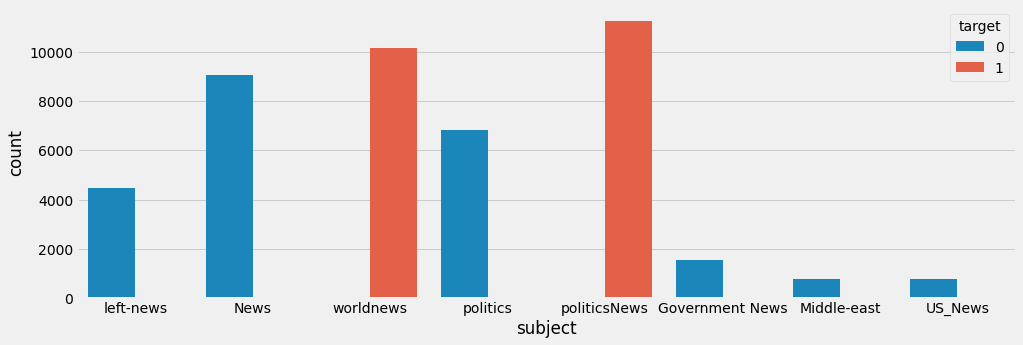

In [16]:
# there are shown the dependence between the the data by topics
plt.style.use('fivethirtyeight')
plt.figure(figsize=(15,5))
sns.countplot(x='subject',data=df,hue='target')

Task 1

Besides the default style, matplotlib comes with several built-in styles that we can use readily. For example, 'fivethirtyeight' is one of this. we can see that this one has a different background color, it has grid lines, there are no spines whatsoever, the weight and the font size of the major tick labels are different.

Task 2

As you can see the most popular subject in our data is 'politicsNews' and 'worldnews' and than a little bit less 'news'. 


In [17]:
#Combine text and title columns:
df['text']=df['text']+" "+df['title']


In [18]:
#Delete insignificant columns from the dataframe:
df.drop(['title','subject','date'],axis=1,inplace=True)
df.head()


,text,target
0,"On June 10, people in at least 27 cities are g...",0
1,While Republicans whine and complain that thei...,0
2,LONDON (Reuters) - Prime Minister Theresa May ...,1
3,NAIROBI (Reuters) - Kenyan President Uhuru Ken...,1
4,COLOMBO (Reuters) - European lawmakers said on...,1


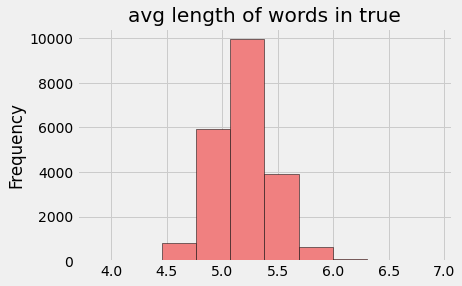

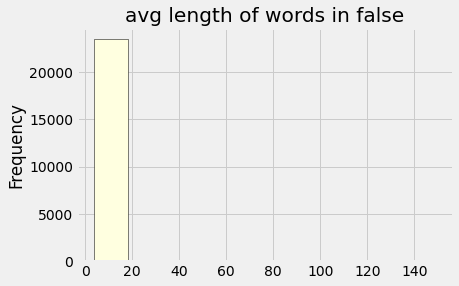

In [ ]:
#Count and plot average length of words in real & fake news.
avg_len_word=df[df['target']==1].text.str.split().map(lambda
x:np.mean([len(word) for word in x]))
avg_len_word.plot(kind='hist',edgecolor='black',color='lightcoral',title='avg length of words in true')
plt.show()
avg_len_word=df[df['target']==0].text.str.split().map(lambda
x:np.mean([len(word) for word in x]))
avg_len_word.plot(kind='hist',edgecolor='black',color='lightyellow',title='avg length of words in false')
plt.show()


Task 3

As we can see the frequency of words in fake news more than 20000 and their lenghth less then 20.

On the other one in true news the most frequency of words less than 10000 and the avarage of length of words is distributed more than in fake news.

In [ ]:
from collections import Counter
# add a column ‘temp_list’ with separate words to dataframe
df['temp_list']=df['text'].apply(lambda x: str(x).split())
# count the frequency of words occurrence 
top=Counter([word for li in df['temp_list'] for word in li])
# form the top 20 most frequently occurring words
temp_1=pd.DataFrame(top.most_common(20))
# set names to columns in temp_1 dataframe and display it in color
temp_1.columns=["most_common_words","frequency"]
temp_1.style.background_gradient(cmap='Blues')


,most_common_words,frequency
0,the,907070
1,to,538754
2,of,441512
3,and,393995
4,a,391144
5,in,327394
6,that,221170
7,on,185433
8,s,172260
9,for,169435


In [ ]:
import plotly.express as pe
import plotly.figure_factory as ff
fig = pe.bar(temp_1, x="frequency", y="most_common_words",
title='Commmon Words in Text', orientation='h',
 width=700, height=700, color='most_common_words')
fig.show()

Task 4

We can see that the most popular words in news it is articles and unions, and the same words with different register of first letter regard as differenet words.

Task 5

In my opinion to analize the news, there are needs to lead to a single register and if it posiible have a some filters to avoid articles and unions. 